In [5]:
import pandas as pd
df=pd.read_csv(r"C:\Users\POOJA\Downloads\NewspaperData.csv")


In [6]:
df.head()

,Newspaper,daily,sunday
0,Baltimore Sun,391.952,488.506
1,Boston Globe,516.981,798.298
2,Boston Herald,355.628,235.084
3,Charlotte Observer,238.555,299.451
4,Chicago Sun Times,537.780,559.093


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 34 entries, 0 to 33
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Newspaper  34 non-null     str    
 1   daily      34 non-null     float64
 2   sunday     34 non-null     float64
dtypes: float64(2), str(1)
memory usage: 1.5 KB


In [9]:
df.isnull().sum()

Newspaper    0
daily        0
sunday       0
dtype: int64

In [10]:
# find correlation
corr=df[['daily','sunday']].corr()


In [11]:
print(corr)

           daily    sunday
daily   1.000000  0.958154
sunday  0.958154  1.000000


<Axes: xlabel='daily', ylabel='sunday'>

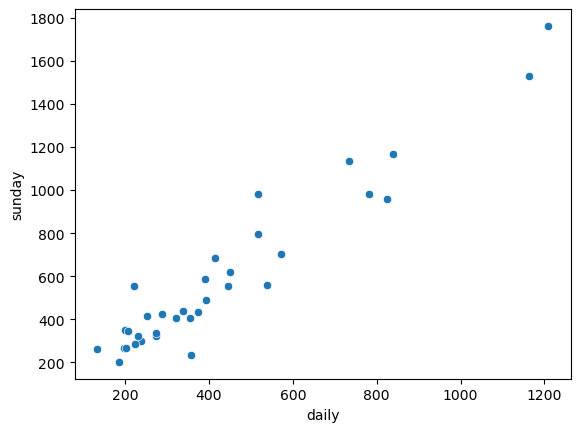

In [12]:
import seaborn as sns
sns.scatterplot(x='daily',y='sunday',data=df)

In [ ]:
df.head(2)

In [13]:
x=df.iloc[:,1]
y=df.iloc[:,-1]
# or
X=df[['daily']] #double brackets=dataframe (2D)
y=df['sunday']  #series(1D) is fine for y

# fitting a linear regression model

In [14]:
# train model [ymx+c]

from sklearn.linear_model import LinearRegression
lin_model=LinearRegression().fit(X,y)

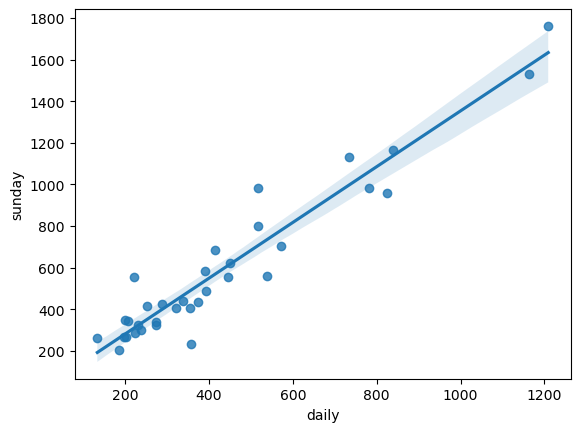

In [15]:
sns.regplot(x="daily",y="sunday",data=df);

In [17]:
# model parameters
print("y=Intercept:",lin_model.intercept_)
print("M=Scope:",lin_model.coef_[0])

y=Intercept: 13.835629909636168
M=Scope: 1.3397147576841257


In [18]:
x.values

array([ 391.952,  516.981,  355.628,  238.555,  537.78 ,  733.775,
        198.832,  252.624,  206.204,  231.177,  449.755,  288.571,
        185.736, 1164.388,  444.581,  412.871,  272.28 ,  781.796,
       1209.225,  825.512,  223.748,  354.843,  515.523,  220.465,
        337.672,  197.12 ,  133.239,  374.009,  273.844,  570.364,
        391.286,  201.86 ,  321.626,  838.902])

In [20]:
# model prediction
y_pred=lin_model.predict(X)
print(y_pred)

[ 538.93950861  706.44270505  490.27570976  333.43128393  734.3074323
  996.88482623  280.21379461  352.27973085  290.0901718   323.54686845
  616.37904075  400.43845725  262.66889014 1573.78341718  609.4473566
  566.96500163  378.61316413 1061.21926861 1633.85220777 1119.78623895
  313.59412751  489.22403367  704.48940094  309.19584396  466.21979157
  277.92020294  192.33788451  514.90100672  380.70847801  777.96069796
  538.04725858  284.2704509   444.72272856 1137.72501956]


In [22]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
# Accuracy metrics
r2=r2_score(y,y_pred)
mse=mean_squared_error(y,y_pred)
mae=mean_absolute_error(y,y_pred)

print("R2 Score:",r2)
print("mean squared error:",mse)
print("mean_absolute_error:",mae)

R2 Score: 0.9180596895873295
mean squared error: 11268.6920722415
mean_absolute_error: 80.1327444999346


In [23]:
# example prediction

daily_val=816.9
predicted_sunday=lin_model.predict([[daily_val]])
predicted_sunday

C:\Users\POOJA\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([1108.24861546])

In [25]:
# predict for daily circulation

newdata=pd.Series([995,8545,5367,500])
data_pred=pd.DataFrame(newdata,columns=['daily'])

In [27]:
lin_model.predict(data_pred)

array([ 1346.85181381, 11461.69823432,  7204.0847344 ,   683.69300875])